# Exploring an opt-in HoloViews backend for `mu.pl.embedding`

**Goal.** Scanpy now has an opt-in HoloViews backend for `sc.pl` (matplotlib stays the default). This notebook explores the same idea for Muon, on the branch `holoviews-backend-prototype`:

```python
mu.pl.embedding(mdata, basis="rna:X_umap", color="rna:bulk_labels", backend="holoviews")
```

**What changed on the branch**

| File | Change |
| --- | --- |
| `src/muon/_hv.py` (new) | Lazy-imports holoviews / hv-anndata and draws the plot with the `A` accessor |
| `src/muon/pl.py` | `embedding` gets `backend="matplotlib" \| "holoviews"`; the three `sc.pl.embedding` call sites dispatch on it |
| `tests/test_muon_plot.py` | New tests (the HoloViews ones skip if holoviews / hv-anndata are missing) |
| `pyproject.toml`, `CHANGELOG.md` | New optional `holoviews` extra; changelog entry |

**Design choice to check with maintainers:** a per-call `backend` argument is the least invasive option. A global switch like scanpy's preset (e.g. via `mu.set_options`) is the alternative.

Run this notebook in the scratch environment (`muon-sandbox`), where Muon is installed in editable mode from the branch.

## 0. Setup

/home/ethomas/projects/muon-sandbox/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
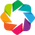

muon        0.1.dev653+gcb4666ee7
mudata      0.4.1
anndata     0.13.4
scanpy      1.13.0a2
holoviews   1.24.0a2
hv-anndata  0.1.2
bokeh       3.10.2rc1


In [1]:
from importlib.metadata import version

import anndata as ad
import holoviews as hv
import muon as mu
import numpy as np
import scanpy as sc

hv.extension("bokeh")

for pkg in ("muon", "mudata", "anndata", "scanpy", "holoviews", "hv-anndata", "bokeh"):
    print(f"{pkg:<11}", version(pkg))

## 1. A toy MuData

`pbmc68k_reduced` (with its UMAP) is the `rna` modality. `prot` is a made-up second modality with random values, just so there is something to colour by that lives in another modality.

`bulk_labels` and `S_score` are columns of the *rna* modality's `.obs`, not of the MuData's own `.obs`, so we pull them up. They then show up prefixed: `rna:bulk_labels`, `rna:S_score`.

In [2]:
rna = sc.datasets.pbmc68k_reduced()

rng = np.random.default_rng(0)
prot = ad.AnnData(X=rng.random((rna.n_obs, 5)).astype("float32"))
prot.obs_names = rna.obs_names
prot.var_names = [f"prot{i}" for i in range(5)]

mdata = mu.MuData({"rna": rna, "prot": prot})
mdata.pull_obs(["bulk_labels", "S_score"])
print(mdata)
print(mdata.obs.columns.tolist())

MuData object with n_obs × n_vars = 700 × 770
  2 modalities
    rna:	700 × 765
      obs:	'bulk_labels', 'n_genes', 'percent_mito', 'n_counts', 'S_score', 'G2M_score', 'phase', 'louvain'
      var:	'n_counts', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
      uns:	'bulk_labels_colors', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts', None
      obsp:	'connectivities', 'distances'
    prot:	700 × 5
      layers:	None
['rna:bulk_labels', 'rna:S_score']


## 2. Baseline: the current matplotlib plot

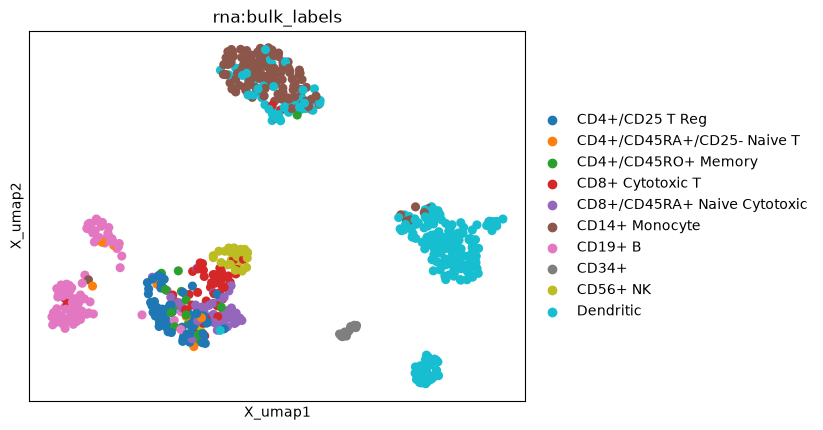

In [3]:
mu.pl.embedding(mdata, basis="rna:X_umap", color="rna:bulk_labels")

## 3. The same call with `backend="holoviews"`

Check in the plot: points coloured by cell type with a legend, a hover tooltip, and the pan / zoom / box-zoom tools in the toolbar.

In [4]:
plot = mu.pl.embedding(mdata, basis="rna:X_umap", color="rna:bulk_labels", backend="holoviews")
plot

:Scatter   [A.obsm['X_umap'][:, 0]]   (X_umap 1,rna:bulk_labels)

## 4. Several colours: categorical and continuous

Several `color` keys give a `holoviews.Layout` (one plot per key), like scanpy giving a list of axes. A numeric column gets a colourbar instead of a legend.

In [5]:
mu.pl.embedding(mdata, basis="rna:X_umap", color=["rna:bulk_labels", "rna:S_score"], backend="holoviews")

:Layout
   .Scatter.I  :Scatter   [A.obsm['X_umap'][:, 0]]   (X_umap 1,rna:bulk_labels)
   .Scatter.II :Scatter   [A.obsm['X_umap'][:, 0]]   (X_umap 1,rna:S_score)

## 5. Colouring by features from different modalities

This is the part of `mu.pl.embedding` that is specific to Muon: `CST3` is a gene in `rna`, `prot0` is a feature of `prot`. The existing code finds out which modality holds each key and joins the values into the cell table before plotting; the HoloViews backend reuses all of that and only replaces the final drawing call.

In [6]:
mu.pl.embedding(mdata, basis="rna:X_umap", color=["CST3", "prot0"], backend="holoviews")

:Layout
   .Scatter.I  :Scatter   [A.obsm['X_umap'][:, 0]]   (X_umap 1,CST3)
   .Scatter.II :Scatter   [A.obsm['X_umap'][:, 0]]   (X_umap 1,prot0)

## 6. Customising with bokeh options

Extra keyword arguments go to `.opts()` of each element and override the defaults. They are *bokeh* options, not scanpy / matplotlib ones, so e.g. `show=False` or `palette=...` do not carry over. You can also keep calling `.opts()` on the returned object.

In [7]:
p = mu.pl.embedding(
    mdata,
    basis="rna:X_umap",
    color="rna:bulk_labels",
    backend="holoviews",
    size=4,
    tools=["hover", "box_select", "lasso_select"],
)
p.opts(title="Custom options")

:Scatter   [A.obsm['X_umap'][:, 0]]   (X_umap 1,rna:bulk_labels)

## 7. Errors that should be informative

In [8]:
try:
    mu.pl.embedding(mdata, basis="rna:X_umap", color="rna:bulk_labels", backend="plotly")
except ValueError as e:
    print("ValueError:", e)

# A plain AnnData has no other modalities to look features up in:
adata_only = ad.AnnData(obs=mdata.obs, obsm=rna.obsm)
try:
    mu.pl.embedding(adata_only, basis="X_umap", color="CST3", backend="holoviews")
except NotImplementedError as e:
    print("NotImplementedError:", e)

ValueError: Unknown plotting backend 'plotly'. Choose 'matplotlib' or 'holoviews'.
NotImplementedError: ['CST3'] not found in .obs. The holoviews backend can only colour by .obs columns for a plain AnnData; for a MuData, features from any modality are supported.


## 8. Why the plot is built from a temporary AnnData

Passing the `MuData` itself to HoloViews (`hv.Scatter(mdata, ...)`) **hangs**: hv-anndata only registers a HoloViews interface for `AnnData`, so HoloViews falls back to its dictionary interface, which unpacks the object with `zip(*data)`. That calls `mdata[0]`, `mdata[1]`, ... and every call returns a new `MuData` view, so the loop never ends (100% CPU, memory growing past 2 GB). **Do not run it.**

So `mu.pl.embedding` does what it already does for scanpy: gather the embedding and the colour columns into a temporary `AnnData`, and hand that to the plotting library. The alternative (a `MuData` interface in hv-anndata) would be cleaner long term but lives in another repository.

## 9. Save as a standalone interactive page

In [9]:
hv.save(plot, "muon_hv.html")

## Open questions / next steps

- Which switch do the maintainers prefer: per-call `backend=` (this branch), or a global option like scanpy's preset?
- `mu.set_options` (`src/muon/config.py`) looked broken when I read it (empty `OPTIONS`; `_apply` called with `**kwargs` but defined with one positional argument). Confirm by running it before relying on it for a global switch.
- Other `mu.pl` functions (`scatter`, `histogram`, `mofa_loadings`) are untouched.
- Linked selections across modalities (select cells in one embedding, see them highlighted in another) would be the feature that scanpy does not have; hv-anndata's `ManifoldMap` / `Dotmap` use `hv.link_selections` for this.
- hover is not on by default in the scanpy 1.13.0a2 preview; this branch turns it on explicitly.